In [1]:
import gymnasium as gym
from IPython.display import display
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
import numpy as np
from environments import create_env
from utils import plot_all_PPO_policies_from_folder, plot_all_q_learning_policies_from_folder
from stable_baselines3 import PPO

# Cas 1: 8x8 par défaut

## Environnement

c:\git\rl_frozen_313\rl_frozen_313\Lib\site-packages\pygame\pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


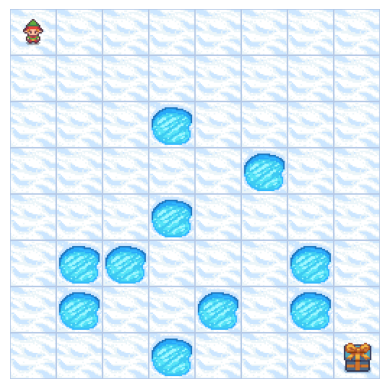

In [2]:
ENV_TYPE = "8x8_default"

env_8x8 = create_env(env_type=ENV_TYPE)
state, info = env_8x8.reset()

plt.imshow(env_8x8.render())
plt.axis("off")
plt.show()

## Politique apprise

### Q-learning

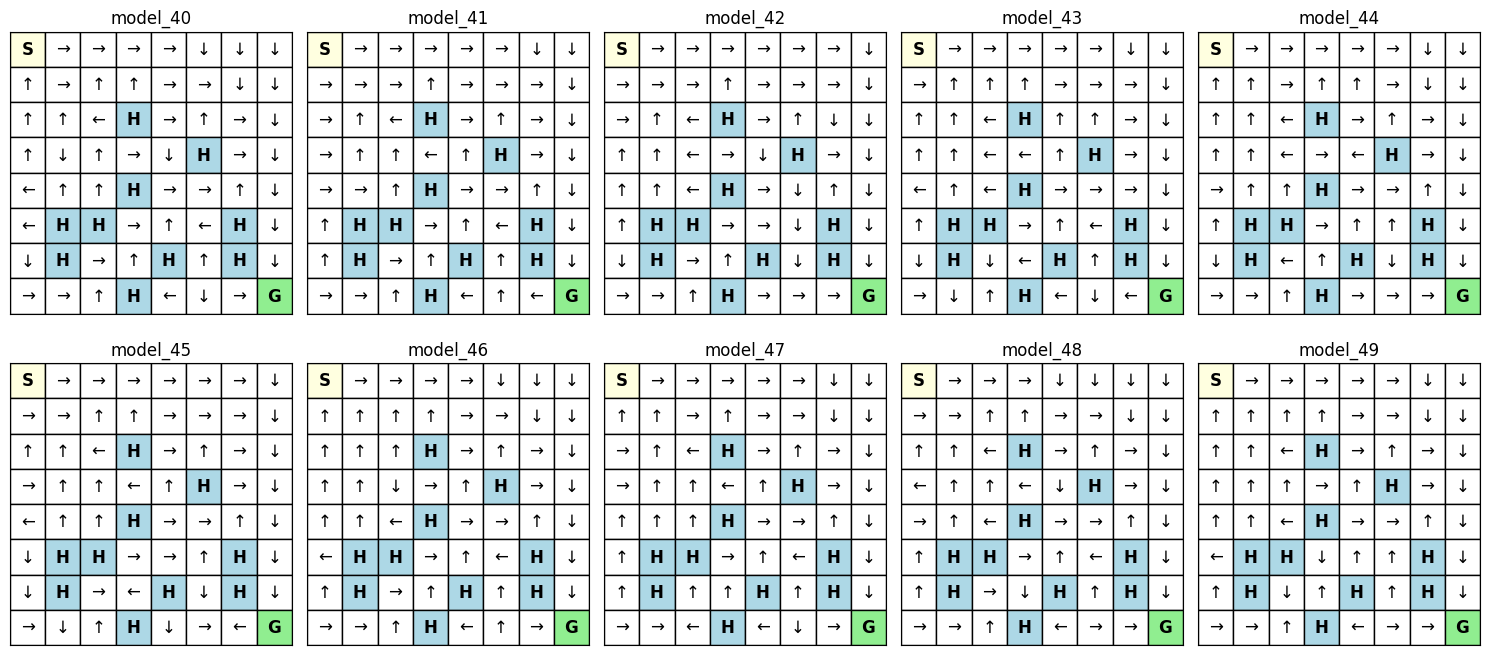

In [4]:
ENV_TYPE = "8x8_default"
plot_all_q_learning_policies_from_folder(ENV_TYPE, folder="./q_learning_8x8_default", ncols=5)

## PPO

c:\git\rl_frozen_313\rl_frozen_313\Lib\site-packages\stable_baselines3\common\on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


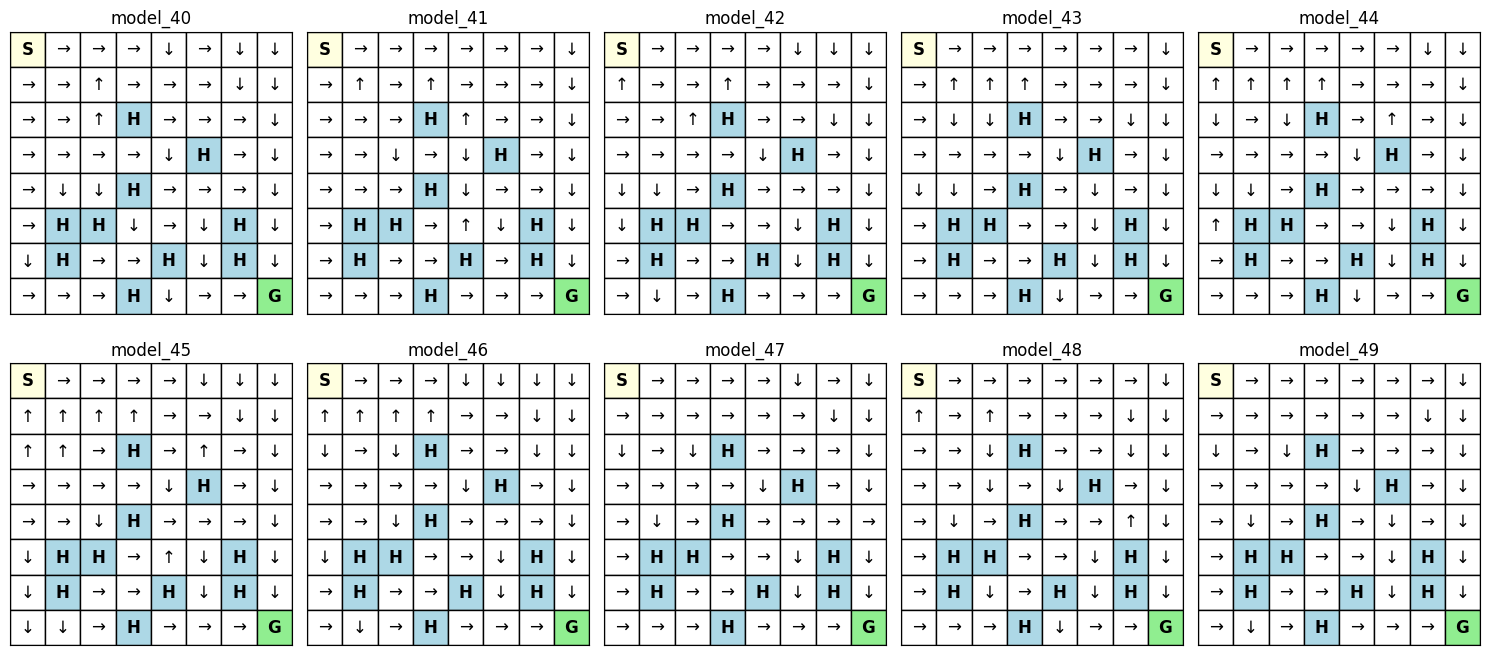

In [5]:
plot_all_PPO_policies_from_folder(ENV_TYPE, "PPO", folder="./ppo_8x8_default", ncols=5)

### P3O

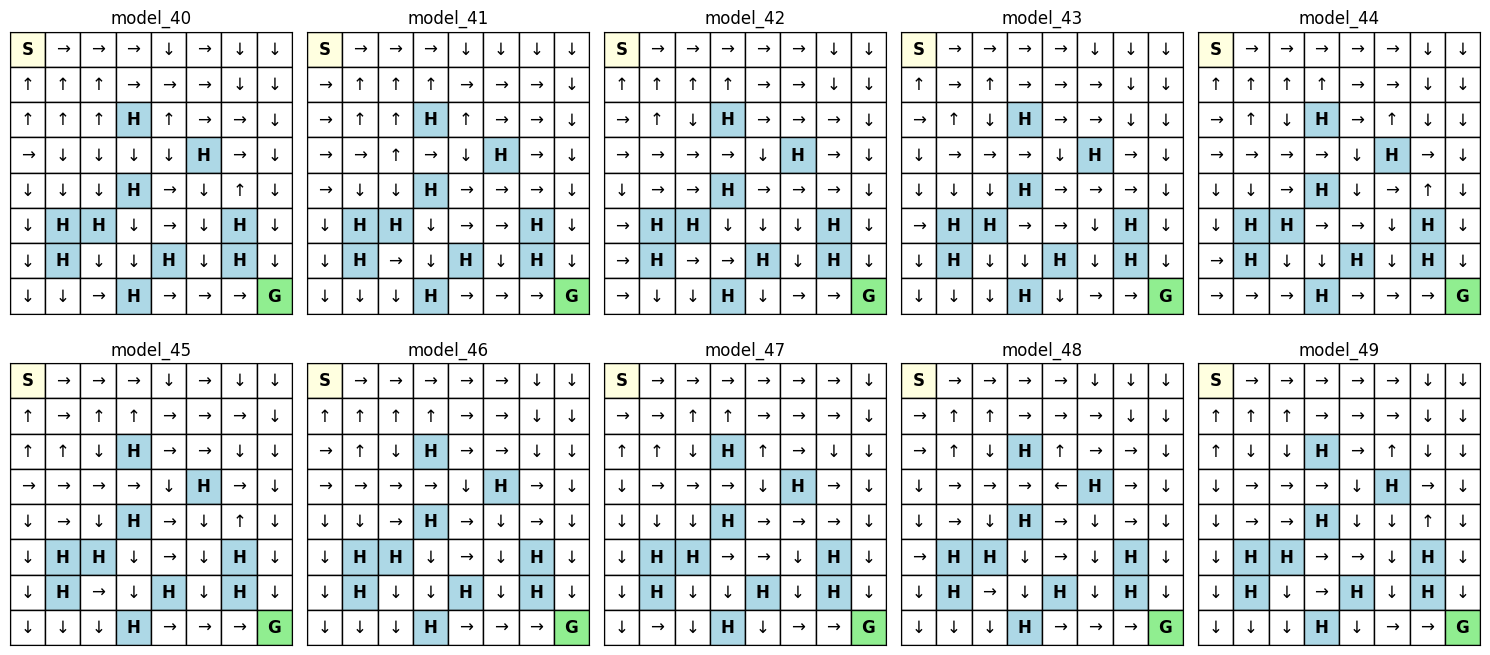

In [6]:
plot_all_PPO_policies_from_folder(ENV_TYPE, "P3O", folder="./p3o_8x8_default", ncols=5)

# Cas 2: Custom 10 x 10

## Environnement

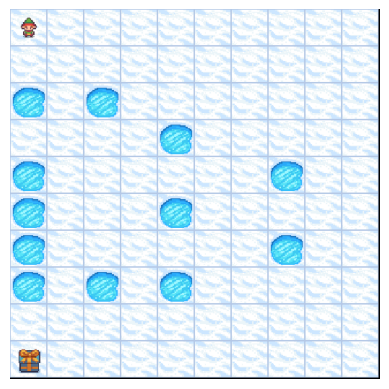

In [7]:
ENV_TYPE = "10x10_custom"

env_10x10 = create_env(env_type=ENV_TYPE)
state, info = env_10x10.reset()

plt.imshow(env_10x10.render())
plt.axis("off")
plt.show()

## Politique apprise

### Q-learning

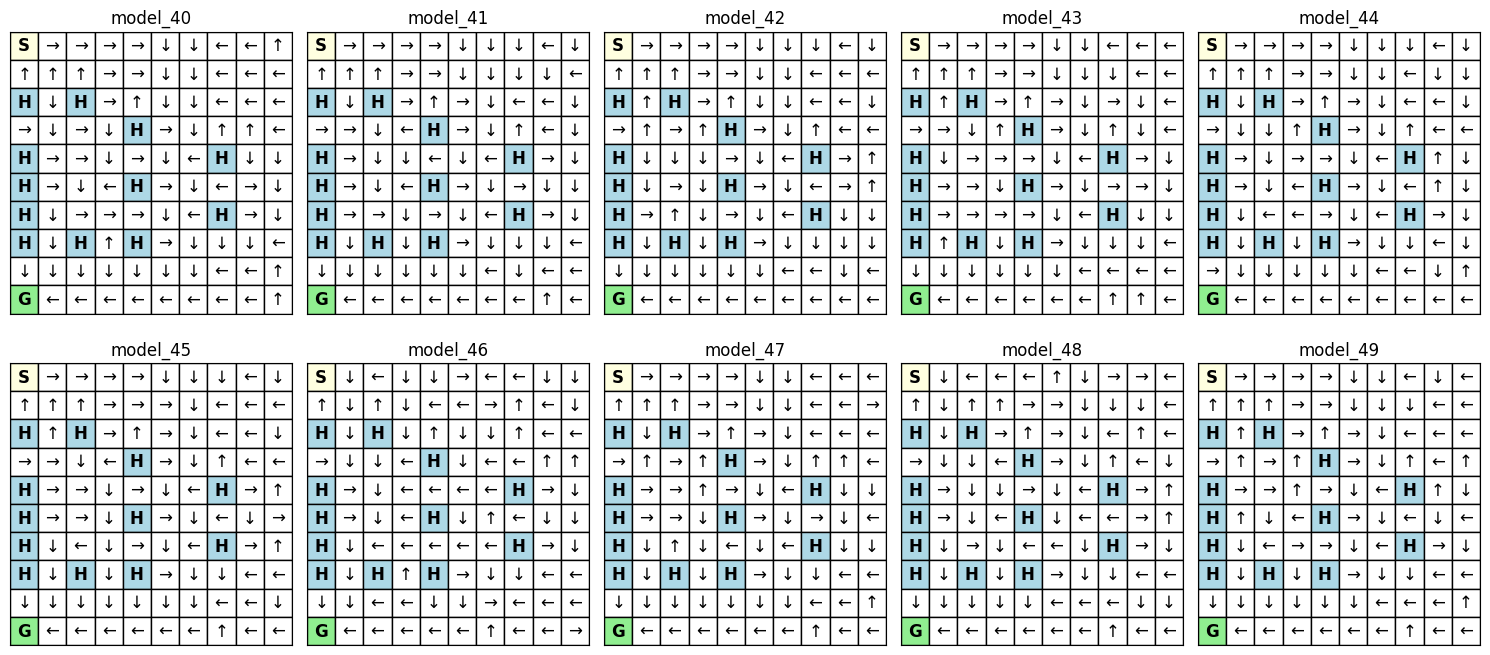

In [8]:
ENV_TYPE = "10x10_custom"
plot_all_q_learning_policies_from_folder(ENV_TYPE, folder="./q_learning_10x10_custom", ncols=5)

### PPO

c:\git\rl_frozen_313\rl_frozen_313\Lib\site-packages\stable_baselines3\common\on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


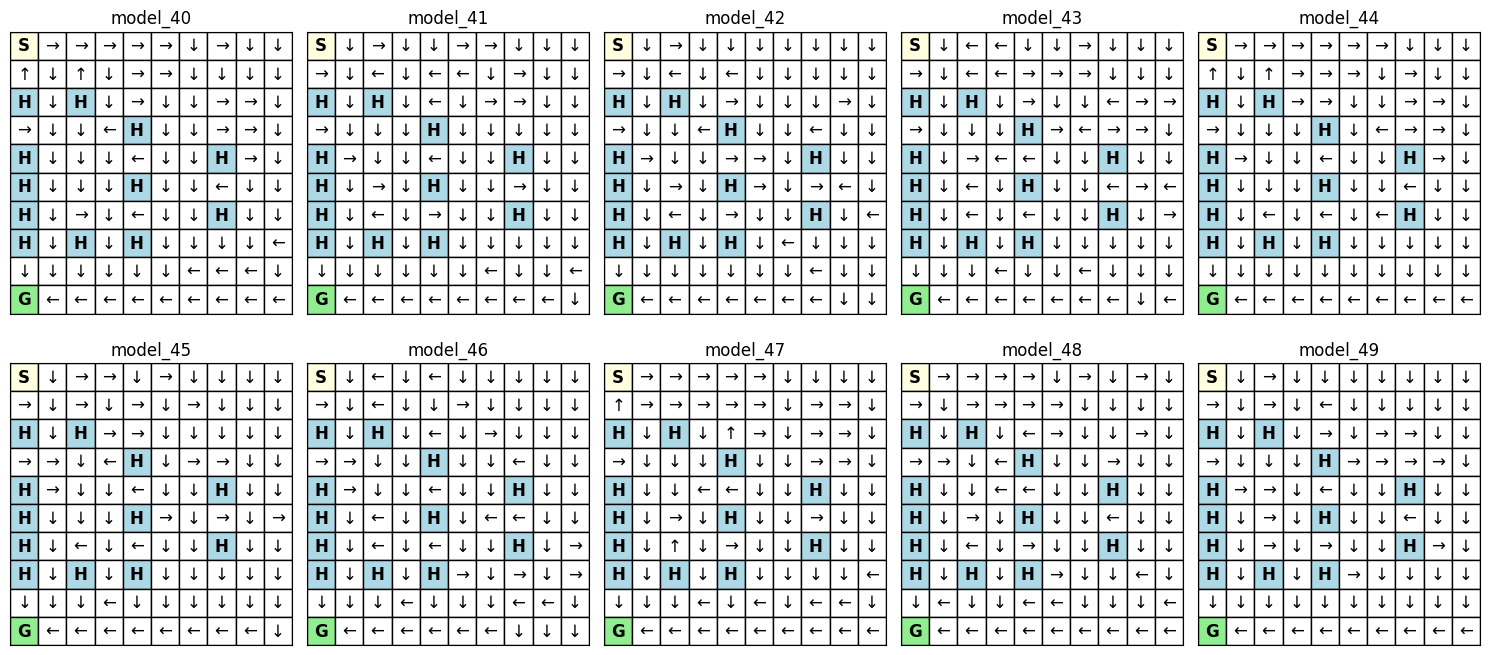

In [9]:
plot_all_PPO_policies_from_folder(ENV_TYPE, "PPO", folder="./ppo_10x10_custom", ncols=5)

### P3O

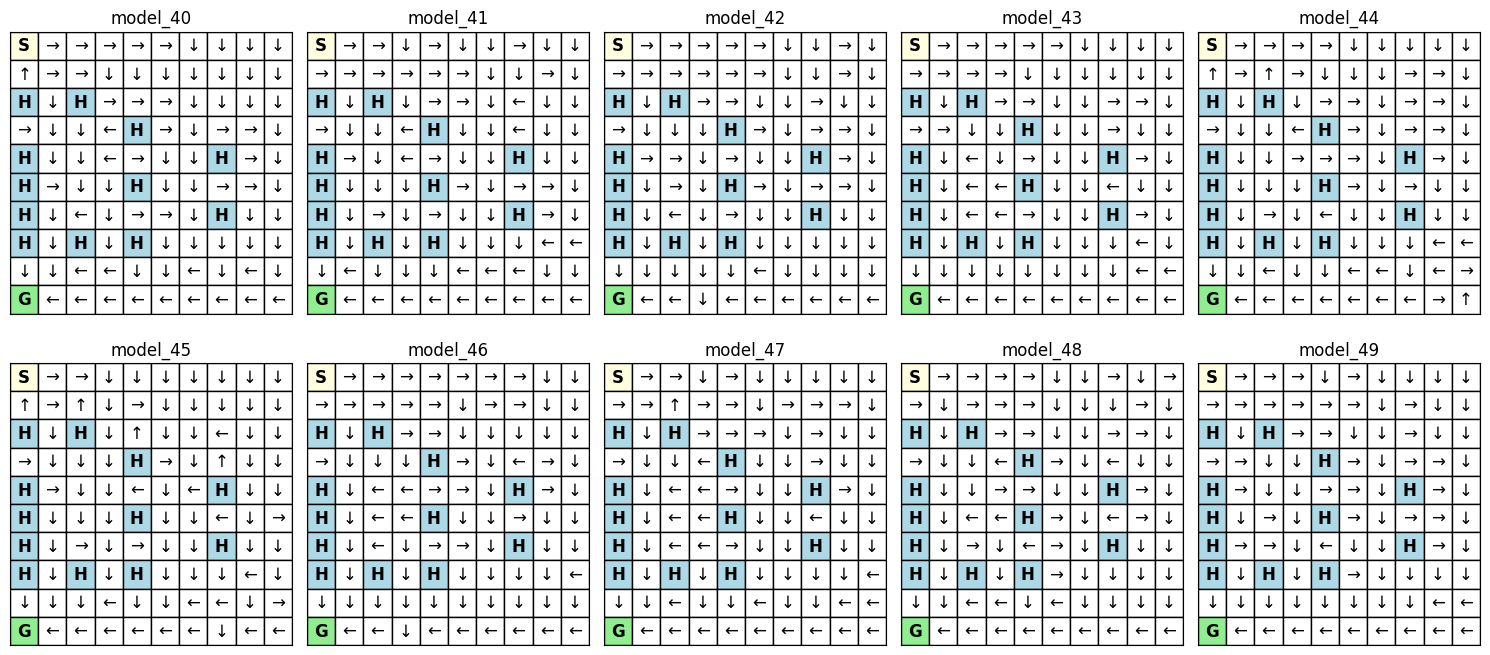

In [10]:
plot_all_PPO_policies_from_folder(ENV_TYPE, "P3O", folder="./p3o_10x10_custom", ncols=5)

# Cas 3: 16 x 16 aléatoires

## Environnement

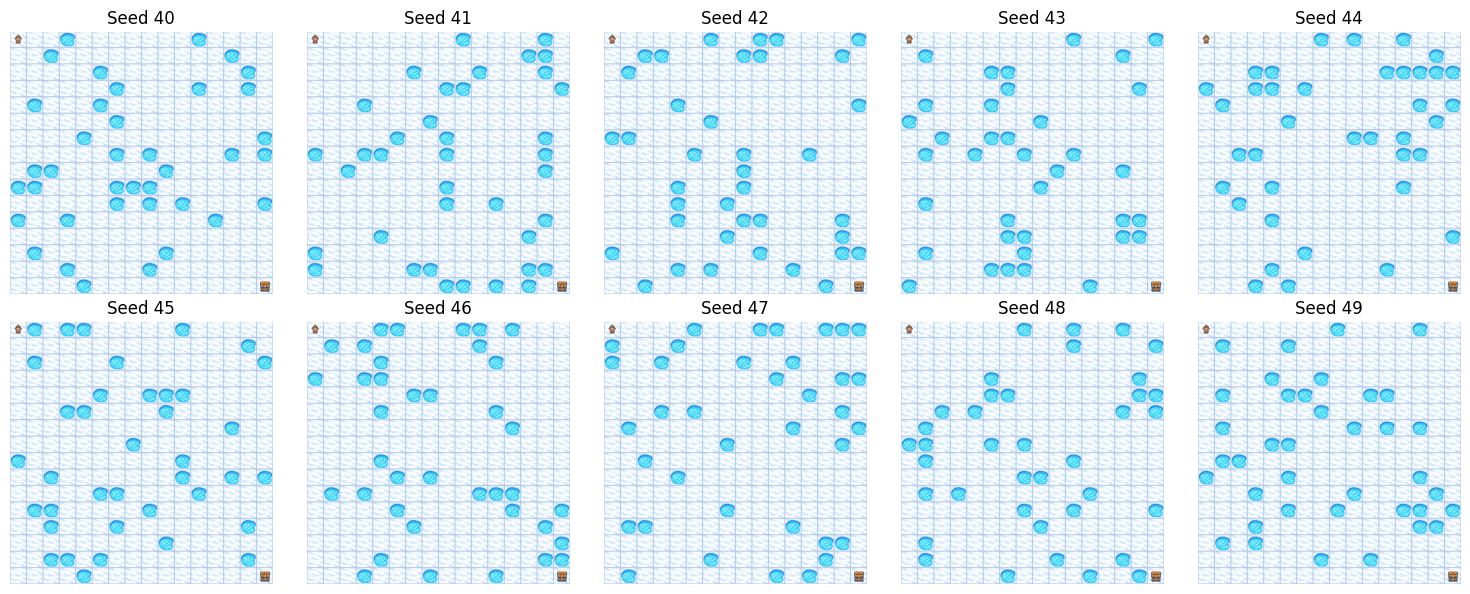

In [11]:
ENV_TYPE = "16x16_random"
BASE_SEED = 40
N_REPETITIONS = 10

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for i in range(N_REPETITIONS):
    row = i // 5
    col = i % 5

    env_16x16 = create_env(env_type=ENV_TYPE, seed = BASE_SEED + i)
    state, info = env_16x16.reset()

    #sauvegarder l'environnement
    #desc = env_16x16.unwrapped.desc
    #desc_str = desc.astype(str)
    #np.save(f"./16x16_maps/desc_{BASE_SEED + i}.npy", desc_str)

    axes[row, col].imshow(env_16x16.render())
    axes[row, col].set_title(f"Seed {BASE_SEED + i}")
    axes[row, col].axis("off")

plt.tight_layout()
plt.show()

## Politique apprise

### Q-learning

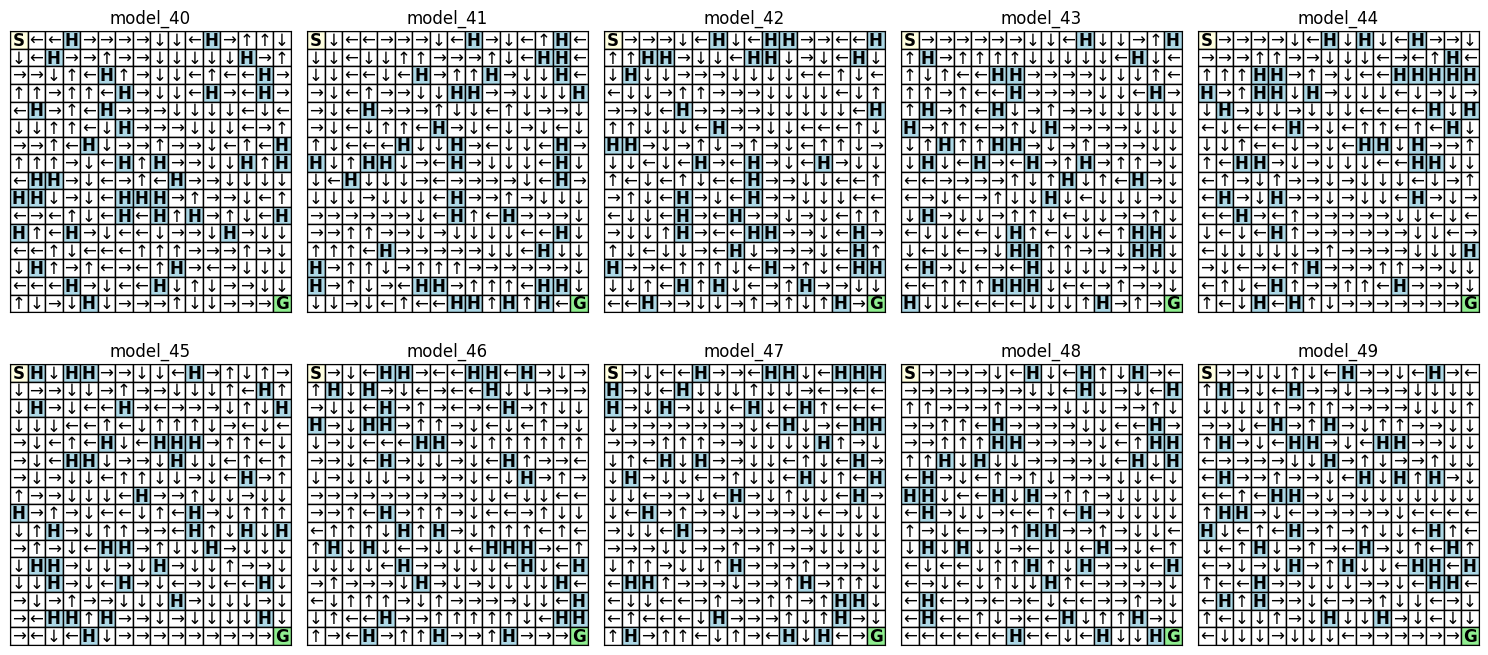

In [12]:
ENV_TYPE = "16x16_random"
plot_all_q_learning_policies_from_folder(ENV_TYPE, folder="./q_learning_16x16_random", ncols=5)

### PPO

c:\git\rl_frozen_313\rl_frozen_313\Lib\site-packages\stable_baselines3\common\on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


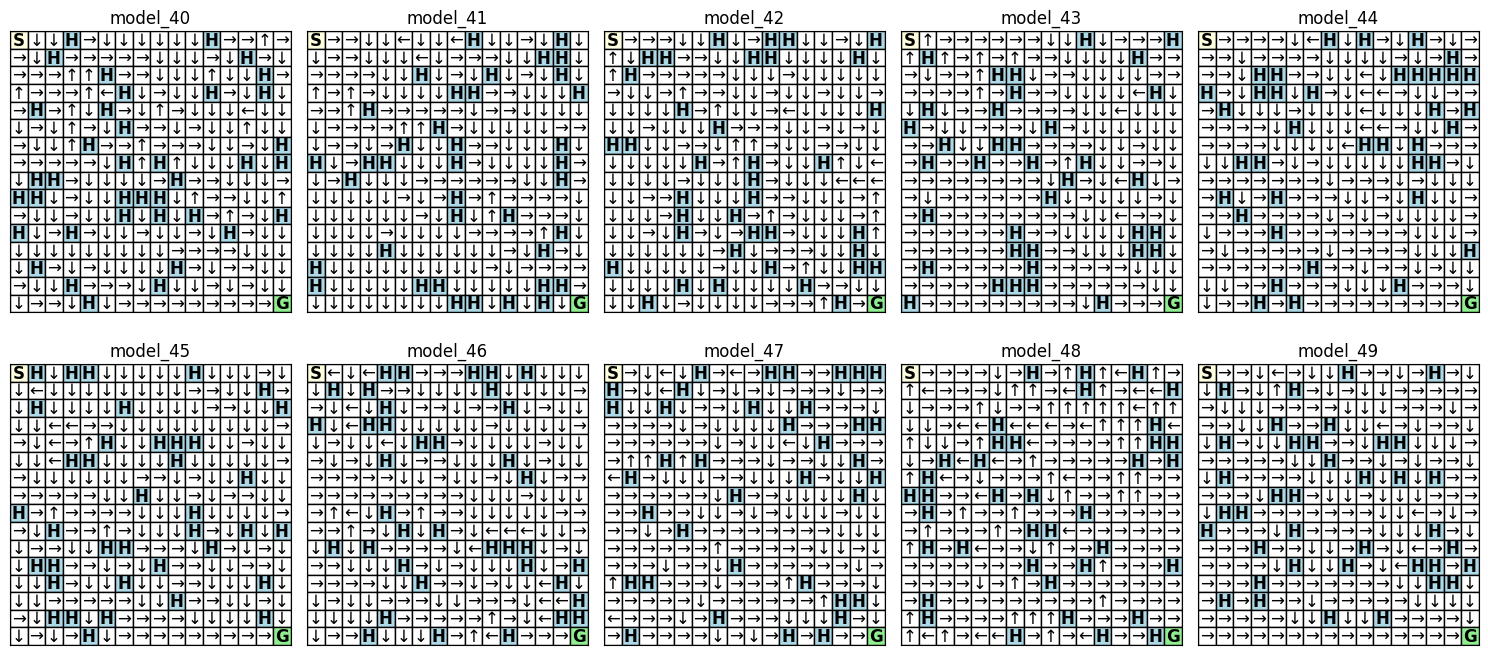

In [13]:
plot_all_PPO_policies_from_folder(ENV_TYPE, "PPO", folder="./ppo_16x16_random", ncols=5)

### P3O

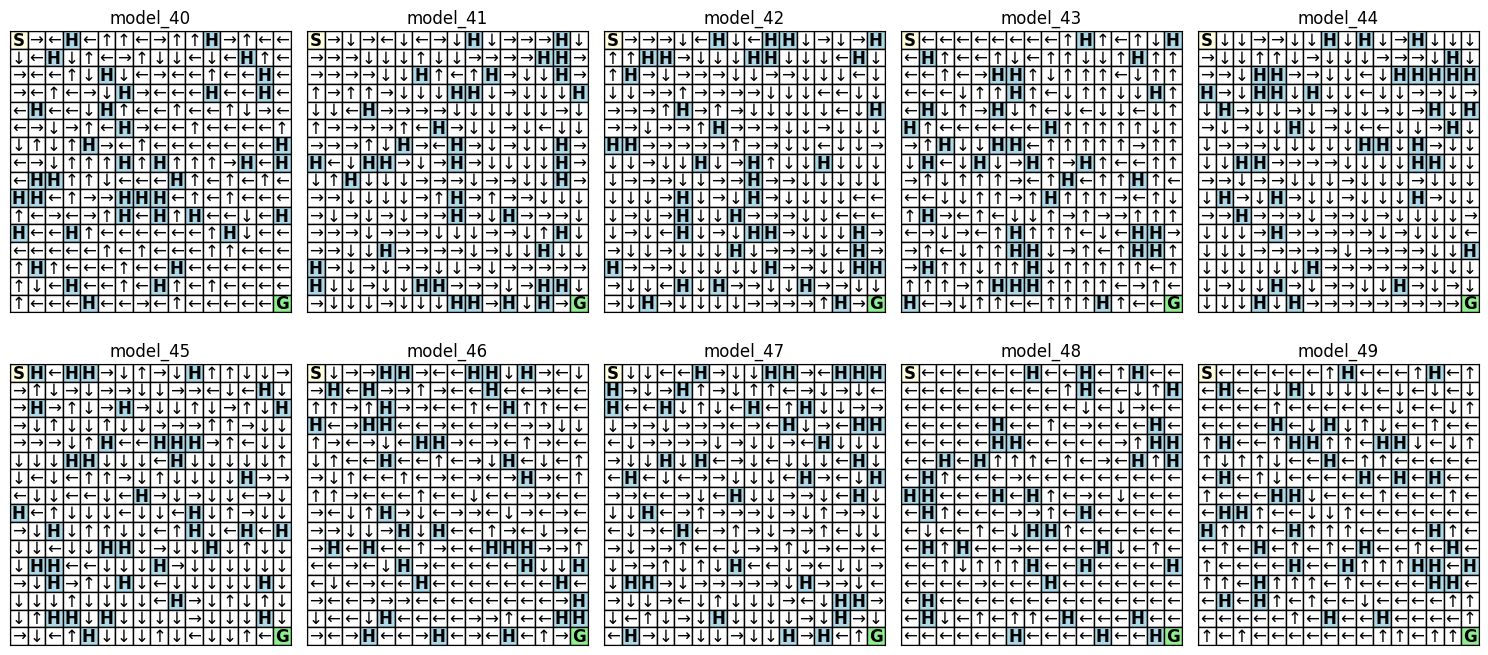

In [14]:
plot_all_PPO_policies_from_folder(ENV_TYPE, "P3O", folder="./p3o_16x16_random", ncols=5)

# Cartes du risque

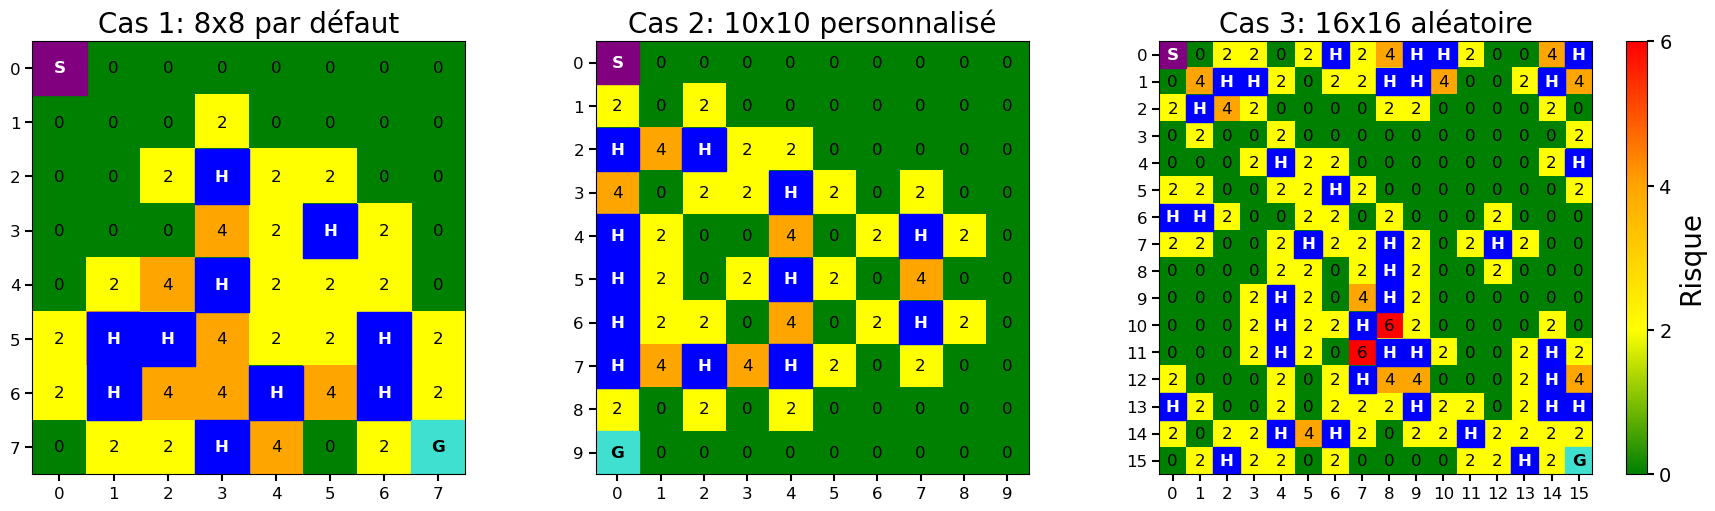

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)

im1 = env_8x8.env.plot_risk_map(ax=axes[0], title="Cas 1: 8x8 par défaut", show_colorbar=False)
im2 = env_10x10.env.plot_risk_map(ax=axes[1], title="Cas 2: 10x10 personnalisé", show_colorbar=False)
im3 = env_16x16.env.plot_risk_map(ax=axes[2], title="Cas 3: 16x16 aléatoire", show_colorbar=False)

# Une seule colorbar commune à droite
cbar = fig.colorbar(im3, ax=axes, fraction=0.025, pad=0.02)
cbar.set_ticks([0, 2, 4, 6])
cbar.ax.tick_params(labelsize=14, width=1.5, length=5)
cbar.set_label("Risque", fontsize=20)

# Enregistrer la figure
plt.savefig(r".\Figures\Figure_carte_de_risque.png", dpi=300, bbox_inches='tight')
plt.show()